# Reinforcement Learning Project

## Q-Learning for Optimal Pathfinding in Gridworld

**Nama:** Fauzan Tamma Harish Kunfaza  
**Algoritma:** Q-Learning  
**Environment:** Gridworld

### Video Presentasi
Link video YouTube: *[(https://youtu.be/VNBD2QmusoY)]*

---

## 1. Pendahuluan

Reinforcement Learning (RL) merupakan salah satu pendekatan dalam Machine Learning yang memungkinkan agent belajar melalui interaksi dengan environment. Dalam Reinforcement Learning, agent melakukan suatu tindakan (action), menerima reward atau penalty, dan memperbarui strategi berdasarkan pengalaman yang diperoleh.

Pada project ini, Reinforcement Learning diterapkan pada permasalahan navigasi dalam Gridworld Environment. Agent berupa robot virtual diharapkan mampu menemukan jalur dari titik awal (Start) menuju titik tujuan (Goal) dengan menghindari obstacle yang terdapat pada environment.

Agent tidak diberikan jalur optimal secara langsung, melainkan harus mempelajari strategi pergerakan melalui proses trial and error. Setiap tindakan yang dilakukan akan menghasilkan reward atau penalty yang digunakan untuk memperbarui pengetahuan agent.

Algoritma yang digunakan dalam project ini adalah Q-Learning, yaitu algoritma Reinforcement Learning yang mempelajari nilai dari setiap tindakan pada suatu state melalui Q-Value. Dengan menggunakan metode epsilon-greedy, agent dapat melakukan eksplorasi terhadap environment sekaligus memanfaatkan strategi yang telah dipelajari.

### Tujuan Project

1. Mengimplementasikan konsep dasar Reinforcement Learning pada Gridworld Environment.
2. Menerapkan algoritma Q-Learning untuk melatih agent dalam menemukan jalur menuju goal.
3. Mengamati proses pembelajaran agent melalui reward yang diperoleh selama training.
4. Mengevaluasi performa agent berdasarkan keberhasilan mencapai goal dan jumlah langkah yang diperlukan.
5. Menganalisis pengaruh parameter Q-Learning terhadap performa agent.

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

## 2. Environment Design

Environment yang digunakan pada project ini adalah Gridworld berukuran 5 × 5. Agent memulai perjalanan dari posisi Start dan harus mencapai posisi Goal dengan menghindari obstacle.

Environment memiliki beberapa komponen utama:

- Start: posisi awal agent.
- Goal: posisi tujuan agent.
- Obstacle: area yang tidak dapat dilewati.
- Free Cell: area yang dapat dilalui agent.

Agent dapat bergerak ke empat arah, yaitu atas, bawah, kiri, dan kanan. Apabila agent mencoba bergerak keluar dari grid atau menuju obstacle, agent akan menerima penalty.

Setiap pergerakan agent akan menghasilkan reward yang digunakan dalam proses pembelajaran Q-Learning.

In [2]:
# Ukuran grid
GRID_SIZE = 5

# Posisi awal agent
START = (0, 0)

# Posisi tujuan
GOAL = (4, 4)

# Posisi obstacle
OBSTACLES = {
    (1, 1),
    (1, 2),
    (2, 3),
    (3, 0),
    (3, 1)
}

# Daftar action yang dapat dilakukan agent
ACTIONS = {
    0: "Up",
    1: "Down",
    2: "Left",
    3: "Right"
}

# Reward
REWARD_GOAL = 100
REWARD_STEP = -1
REWARD_OBSTACLE = -10
REWARD_OUT_OF_BOUNDS = -5

print("Grid Size:", GRID_SIZE, "x", GRID_SIZE)
print("Start:", START)
print("Goal:", GOAL)
print("Obstacles:", OBSTACLES)
print("Actions:", ACTIONS)

Grid Size: 5 x 5
Start: (0, 0)
Goal: (4, 4)
Obstacles: {(2, 3), (1, 2), (3, 1), (1, 1), (3, 0)}
Actions: {0: 'Up', 1: 'Down', 2: 'Left', 3: 'Right'}


In [3]:
def render_grid(agent_position=None, path=None):
    """
    Menampilkan Gridworld Environment.
    """

    grid = np.zeros((GRID_SIZE, GRID_SIZE))

    # Menandai obstacle
    for obstacle in OBSTACLES:
        grid[obstacle] = 1

    # Menandai Start
    grid[START] = 2

    # Menandai Goal
    grid[GOAL] = 3

    # Menandai jalur agent
    if path is not None:
        for position in path:
            if position not in [START, GOAL] and position not in OBSTACLES:
                grid[position] = 4

    # Menandai posisi agent
    if agent_position is not None:
        grid[agent_position] = 5

    # Membuat visualisasi
    fig, ax = plt.subplots(figsize=(6, 6))

    ax.imshow(grid, cmap="viridis")

    # Menampilkan label setiap cell
    for row in range(GRID_SIZE):
        for col in range(GRID_SIZE):

            if (row, col) == START:
                label = "S"

            elif (row, col) == GOAL:
                label = "G"

            elif (row, col) in OBSTACLES:
                label = "#"

            elif path is not None and (row, col) in path:
                label = "*"

            else:
                label = ""

            if agent_position == (row, col):
                label = "A"

            ax.text(
                col,
                row,
                label,
                ha="center",
                va="center",
                color="white",
                fontsize=15,
                fontweight="bold"
            )

    ax.set_xticks(range(GRID_SIZE))
    ax.set_yticks(range(GRID_SIZE))

    ax.set_title("Gridworld Environment")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")

    plt.grid(True)
    plt.show()

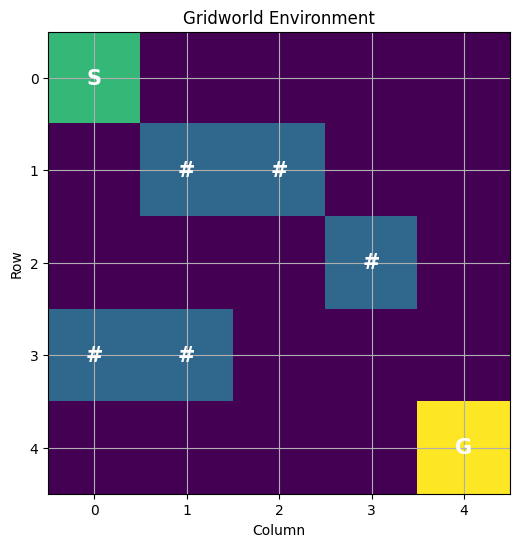

In [4]:
render_grid()

## 3. Agent Actions and Reward System

Agent memiliki empat kemungkinan tindakan, yaitu Up, Down, Left, dan Right.

Setiap tindakan akan mengubah posisi agent sesuai dengan arah pergerakan. Environment akan memeriksa apakah posisi baru agent valid, merupakan obstacle, berada di luar grid, atau merupakan goal.

Reward diberikan berdasarkan hasil tindakan agent.

In [5]:
def reset_environment():
    """
    Mengembalikan agent ke posisi awal.
    """

    return START

In [6]:
def step(position, action):
    """
    Melakukan satu langkah pergerakan agent.

    Parameters:
    position : posisi agent saat ini
    action   : tindakan yang dipilih agent

    Returns:
    next_position : posisi agent setelah melakukan action
    reward       : reward yang diperoleh
    done         : apakah episode telah berakhir
    """

    row, col = position

    # Menentukan posisi baru berdasarkan action
    if action == 0:      # Up
        new_position = (row - 1, col)

    elif action == 1:    # Down
        new_position = (row + 1, col)

    elif action == 2:    # Left
        new_position = (row, col - 1)

    elif action == 3:    # Right
        new_position = (row, col + 1)

    else:
        raise ValueError("Action tidak valid!")

    # Memeriksa apakah posisi keluar dari grid
    if (
        new_position[0] < 0
        or new_position[0] >= GRID_SIZE
        or new_position[1] < 0
        or new_position[1] >= GRID_SIZE
    ):
        return position, REWARD_OUT_OF_BOUNDS, False

    # Memeriksa apakah posisi merupakan obstacle
    if new_position in OBSTACLES:
        return position, REWARD_OBSTACLE, False

    # Memeriksa apakah agent mencapai goal
    if new_position == GOAL:
        return new_position, REWARD_GOAL, True

    # Jika pergerakan valid dan belum mencapai goal
    return new_position, REWARD_STEP, False

In [7]:
position = (1, 0)

next_position, reward, done = step(position, 3)

print("Next Position:", next_position)
print("Reward:", reward)
print("Done:", done)

Next Position: (1, 0)
Reward: -10
Done: False


In [8]:
position = (4, 3)

next_position, reward, done = step(position, 3)

print("Next Position:", next_position)
print("Reward:", reward)
print("Done:", done)

Next Position: (4, 4)
Reward: 100
Done: True


## 4. Q-Learning Agent

Pada tahap ini, agent diimplementasikan menggunakan algoritma Q-Learning. Algoritma ini memungkinkan agent mempelajari nilai dari setiap tindakan berdasarkan pengalaman interaksi dengan environment.

Pengetahuan agent disimpan dalam sebuah Q-Table yang berisi nilai Q-Value untuk setiap kombinasi state dan action.

Q-Value digunakan untuk memperkirakan seberapa baik suatu tindakan apabila dilakukan pada state tertentu.

In [9]:
# Inisialisasi Q-Table
q_table = np.zeros((GRID_SIZE, GRID_SIZE, len(ACTIONS)))

print("Q-Table Shape:", q_table.shape)
print("Initial Q-Table:")
print(q_table)

Q-Table Shape: (5, 5, 4)
Initial Q-Table:
[[[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]

 [[0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]
  [0. 0. 0. 0.]]]


In [10]:
print(q_table[0, 0, 3])

0.0


### 4.1 Q-Learning Hyperparameters

Q-Learning menggunakan beberapa hyperparameter yang mengatur proses pembelajaran agent, yaitu learning rate, discount factor, dan epsilon.

Parameter tersebut menentukan seberapa cepat agent memperbarui pengetahuannya, seberapa besar agent mempertimbangkan reward masa depan, serta seberapa sering agent melakukan eksplorasi.

In [11]:
# Q-Learning Hyperparameters

LEARNING_RATE = 0.1
DISCOUNT_FACTOR = 0.95

EPSILON = 1.0
EPSILON_MIN = 0.01
EPSILON_DECAY = 0.995

print("Learning Rate:", LEARNING_RATE)
print("Discount Factor:", DISCOUNT_FACTOR)
print("Initial Epsilon:", EPSILON)
print("Minimum Epsilon:", EPSILON_MIN)
print("Epsilon Decay:", EPSILON_DECAY)

Learning Rate: 0.1
Discount Factor: 0.95
Initial Epsilon: 1.0
Minimum Epsilon: 0.01
Epsilon Decay: 0.995


### 4.2 Epsilon-Greedy Policy

Epsilon-greedy merupakan strategi pemilihan tindakan yang digunakan untuk menyeimbangkan exploration dan exploitation.

Apabila nilai random lebih kecil dari epsilon, agent akan memilih tindakan secara acak. Sebaliknya, agent akan memilih tindakan dengan Q-Value tertinggi berdasarkan pengetahuan yang tersimpan dalam Q-Table.

Strategi ini memungkinkan agent mencoba berbagai tindakan sekaligus memanfaatkan pengalaman yang telah diperoleh.

In [12]:
def choose_action(state, q_table, epsilon):
    """
    Memilih action menggunakan epsilon-greedy policy.

    Parameters:
    state   : posisi agent saat ini
    q_table : tabel nilai Q
    epsilon : probabilitas eksplorasi

    Returns:
    action : tindakan yang dipilih agent
    """

    # Exploration: memilih action secara acak
    if random.random() < epsilon:
        action = random.choice(list(ACTIONS.keys()))

    # Exploitation: memilih action dengan Q-Value tertinggi
    else:
        q_values = q_table[state[0], state[1]]

        # Mengambil semua action dengan nilai Q tertinggi
        best_actions = np.flatnonzero(
            np.isclose(q_values, np.max(q_values))
        )

        # Memilih secara acak jika terdapat beberapa nilai tertinggi yang sama
        action = random.choice(best_actions.tolist())

    return action

In [13]:
test_state = (0, 0)

# Menguji exploration
exploration_action = choose_action(
    test_state,
    q_table,
    epsilon=1.0
)

# Menguji exploitation
exploitation_action = choose_action(
    test_state,
    q_table,
    epsilon=0.0
)

print("Exploration Action:", ACTIONS[exploration_action])
print("Exploitation Action:", ACTIONS[exploitation_action])

Exploration Action: Up
Exploitation Action: Right


### 4.3 Q-Learning Update

Setelah agent melakukan tindakan dan menerima feedback dari environment, nilai Q-Value akan diperbarui menggunakan persamaan Q-Learning.

Pembaruan dilakukan dengan mempertimbangkan reward yang diterima dan estimasi nilai terbaik pada state berikutnya.

Apabila agent mencapai Goal, proses pembaruan tidak memperhitungkan nilai masa depan karena Goal merupakan terminal state.

In [14]:
def update_q_table(
    q_table,
    state,
    action,
    reward,
    next_state,
    done,
    learning_rate,
    discount_factor
):
    """
    Memperbarui Q-Value berdasarkan pengalaman agent.
    """

    row, col = state
    next_row, next_col = next_state

    # Mengambil nilai Q saat ini
    current_q = q_table[row, col, action]

    # Jika mencapai terminal state
    if done:
        target_q = reward

    # Jika belum mencapai terminal state
    else:
        next_max_q = np.max(q_table[next_row, next_col])

        target_q = reward + discount_factor * next_max_q

    # Menghitung Q-Value baru
    new_q = current_q + learning_rate * (target_q - current_q)

    # Memperbarui Q-Table
    q_table[row, col, action] = new_q

In [15]:
# Membuat Q-Table khusus pengujian
test_q_table = np.zeros((GRID_SIZE, GRID_SIZE, len(ACTIONS)))

# Simulasi agent
test_state = (0, 0)
test_action = 3  # Right
test_reward = -1
test_next_state = (0, 1)
test_done = False

# Memperbarui Q-Value
update_q_table(
    q_table=test_q_table,
    state=test_state,
    action=test_action,
    reward=test_reward,
    next_state=test_next_state,
    done=test_done,
    learning_rate=LEARNING_RATE,
    discount_factor=DISCOUNT_FACTOR
)

print("Q-Value setelah update:")
print(test_q_table[0, 0])

Q-Value setelah update:
[ 0.   0.   0.  -0.1]


In [16]:
# Simulasi mencapai Goal
update_q_table(
    q_table=test_q_table,
    state=(4, 3),
    action=3,              # Right
    reward=REWARD_GOAL,
    next_state=GOAL,
    done=True,
    learning_rate=LEARNING_RATE,
    discount_factor=DISCOUNT_FACTOR
)

print("Q-Value menuju Goal:")
print(test_q_table[4, 3])

Q-Value menuju Goal:
[ 0.  0.  0. 10.]


In [17]:
def get_state_value(state, q_table):
    """
    Mengambil nilai terbaik dari suatu state.
    """

    row, col = state

    return np.max(q_table[row, col])

In [18]:
value = get_state_value((0, 0), test_q_table)

print("State Value:", value)

State Value: 0.0


## 5. Training Q-Learning Agent

Pada tahap ini, agent dilatih menggunakan algoritma Q-Learning melalui interaksi berulang dengan Gridworld Environment.

Training dilakukan dalam sejumlah episode. Pada setiap episode, agent memulai perjalanan dari posisi Start, memilih tindakan menggunakan epsilon-greedy policy, menerima reward dari environment, dan memperbarui Q-Table berdasarkan pengalaman yang diperoleh.

Untuk menghindari proses yang berlangsung terlalu lama, setiap episode memiliki batas maksimum langkah. Selama training, nilai epsilon juga dikurangi secara bertahap agar agent dapat beralih dari exploration menuju exploitation.

In [19]:
# Jumlah episode training
EPISODES = 1000

# Maksimum langkah dalam satu episode
MAX_STEPS = 100

# Mengatur random seed agar hasil eksperimen dapat direproduksi
random.seed(42)
np.random.seed(42)

# Membuat Q-Table baru untuk training
q_table = np.zeros((GRID_SIZE, GRID_SIZE, len(ACTIONS)))

# Mengatur epsilon awal
epsilon = EPSILON

# Menyimpan hasil training
episode_rewards = []
episode_steps = []
success_history = []
epsilon_history = []

print("Training Configuration")
print("----------------------")
print("Episodes:", EPISODES)
print("Maximum Steps:", MAX_STEPS)
print("Initial Epsilon:", epsilon)

Training Configuration
----------------------
Episodes: 1000
Maximum Steps: 100
Initial Epsilon: 1.0


In [20]:
# Memulai proses training
print("Starting Q-Learning Training...\n")

for episode in range(EPISODES):

    # Mengembalikan agent ke posisi awal
    state = reset_environment()

    # Inisialisasi variabel episode
    total_reward = 0
    steps = 0
    done = False

    # Proses interaksi agent dengan environment
    for step_count in range(1, MAX_STEPS + 1):

        # 1. Agent memilih action
        action = choose_action(
            state,
            q_table,
            epsilon
        )

        # 2. Environment memberikan state berikutnya dan reward
        next_state, reward, done = step(
            state,
            action
        )

        # 3. Memperbarui Q-Table
        update_q_table(
            q_table=q_table,
            state=state,
            action=action,
            reward=reward,
            next_state=next_state,
            done=done,
            learning_rate=LEARNING_RATE,
            discount_factor=DISCOUNT_FACTOR
        )

        # 4. Menambahkan reward
        total_reward += reward

        # 5. Memperbarui state agent
        state = next_state

        steps = step_count

        # Menghentikan episode jika mencapai Goal
        if done:
            break

    # Menyimpan hasil setiap episode
    episode_rewards.append(total_reward)
    episode_steps.append(steps)
    success_history.append(1 if done else 0)
    epsilon_history.append(epsilon)

    # Mengurangi epsilon secara bertahap
    epsilon = max(
        EPSILON_MIN,
        epsilon * EPSILON_DECAY
    )

    # Menampilkan progress setiap 100 episode
    if (episode + 1) % 100 == 0:
        print(
            f"Episode: {episode + 1}/{EPISODES} | "
            f"Reward: {total_reward} | "
            f"Steps: {steps} | "
            f"Success: {done} | "
            f"Epsilon: {epsilon:.4f}"
        )

print("\nTraining Completed!")

Starting Q-Learning Training...

Episode: 100/1000 | Reward: 54 | Steps: 17 | Success: True | Epsilon: 0.6058
Episode: 200/1000 | Reward: 73 | Steps: 10 | Success: True | Epsilon: 0.3670
Episode: 300/1000 | Reward: 91 | Steps: 10 | Success: True | Epsilon: 0.2223
Episode: 400/1000 | Reward: 79 | Steps: 13 | Success: True | Epsilon: 0.1347
Episode: 500/1000 | Reward: 93 | Steps: 8 | Success: True | Epsilon: 0.0816
Episode: 600/1000 | Reward: 93 | Steps: 8 | Success: True | Epsilon: 0.0494
Episode: 700/1000 | Reward: 91 | Steps: 10 | Success: True | Epsilon: 0.0299
Episode: 800/1000 | Reward: 93 | Steps: 8 | Success: True | Epsilon: 0.0181
Episode: 900/1000 | Reward: 93 | Steps: 8 | Success: True | Epsilon: 0.0110
Episode: 1000/1000 | Reward: 93 | Steps: 8 | Success: True | Epsilon: 0.0100

Training Completed!


### 5.1 Training Performance Summary

Setelah proses training selesai, dilakukan perhitungan untuk mengetahui performa agent.

Evaluasi awal dilakukan dengan menghitung rata-rata reward, success rate, dan rata-rata jumlah langkah yang diperlukan agent untuk mencapai Goal.

In [21]:
# Menghitung jumlah episode yang berhasil
successful_episodes = sum(success_history)

# Menghitung success rate keseluruhan
overall_success_rate = (
    successful_episodes / EPISODES
) * 100

# Menghitung rata-rata reward
average_reward = np.mean(episode_rewards)

# Mengambil jumlah langkah dari episode yang berhasil
successful_steps = [
    steps
    for steps, success in zip(episode_steps, success_history)
    if success == 1
]

# Menghitung rata-rata langkah ketika berhasil
if len(successful_steps) > 0:
    average_success_steps = np.mean(successful_steps)
else:
    average_success_steps = 0

# Menghitung success rate 100 episode terakhir
last_100_success_rate = (
    np.mean(success_history[-100:]) * 100
)

print("TRAINING PERFORMANCE SUMMARY")
print("=" * 35)

print(f"Total Episodes       : {EPISODES}")
print(f"Successful Episodes  : {successful_episodes}")
print(f"Failed Episodes      : {EPISODES - successful_episodes}")
print(f"Overall Success Rate : {overall_success_rate:.2f}%")
print(f"Last 100 Success Rate: {last_100_success_rate:.2f}%")
print(f"Average Reward       : {average_reward:.2f}")
print(f"Average Success Steps: {average_success_steps:.2f}")

TRAINING PERFORMANCE SUMMARY
Total Episodes       : 1000
Successful Episodes  : 994
Failed Episodes      : 6
Overall Success Rate : 99.40%
Last 100 Success Rate: 100.00%
Average Reward       : 74.58
Average Success Steps: 12.08


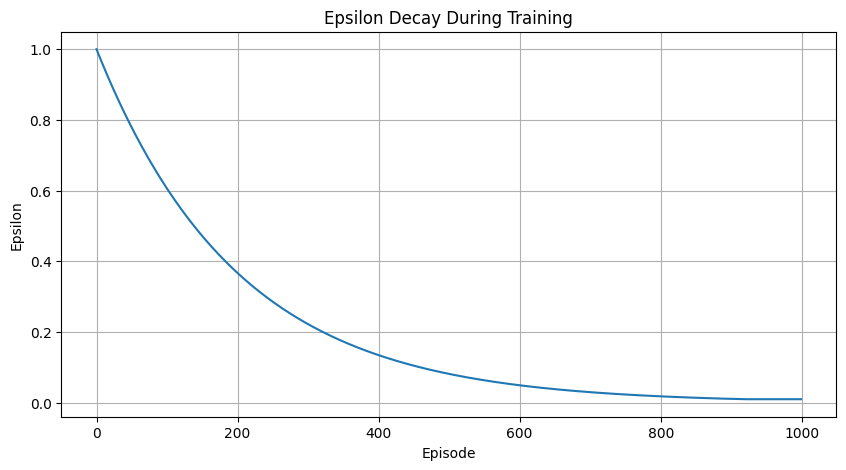

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(epsilon_history)

plt.title("Epsilon Decay During Training")
plt.xlabel("Episode")
plt.ylabel("Epsilon")

plt.grid(True)
plt.show()

### 5.2 Reward Analysis

Reward merupakan salah satu indikator yang digunakan untuk mengamati proses pembelajaran agent.

Pada tahap ini, reward dari setiap episode divisualisasikan untuk mengetahui perubahan performa agent selama training.

Selain reward setiap episode, digunakan moving average dengan window 50 episode untuk melihat tren perkembangan reward secara lebih jelas.

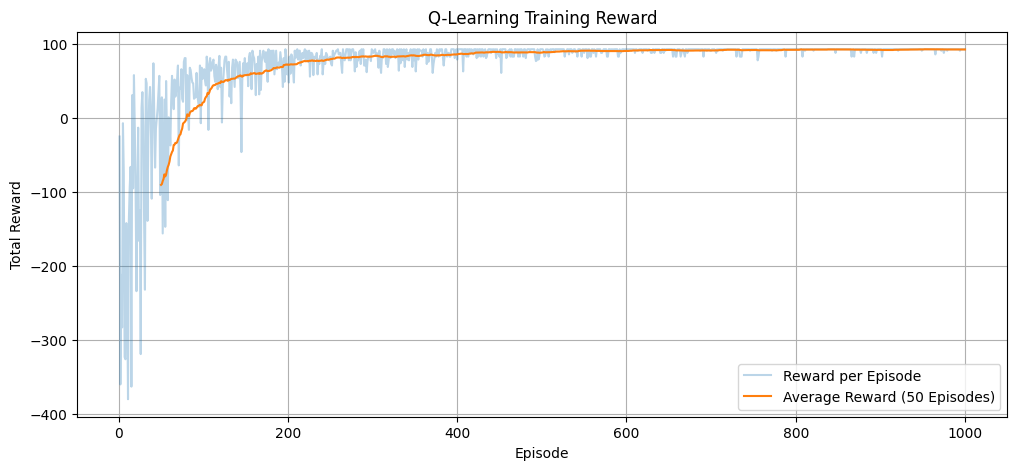

In [23]:
# Mengatur ukuran moving average
WINDOW_SIZE = 50

# Menghitung moving average reward
reward_moving_average = np.convolve(
    episode_rewards,
    np.ones(WINDOW_SIZE) / WINDOW_SIZE,
    mode="valid"
)

# Visualisasi reward
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, EPISODES + 1),
    episode_rewards,
    alpha=0.3,
    label="Reward per Episode"
)

plt.plot(
    range(WINDOW_SIZE, EPISODES + 1),
    reward_moving_average,
    label="Average Reward (50 Episodes)"
)

plt.title("Q-Learning Training Reward")
plt.xlabel("Episode")
plt.ylabel("Total Reward")

plt.legend()
plt.grid(True)
plt.show()

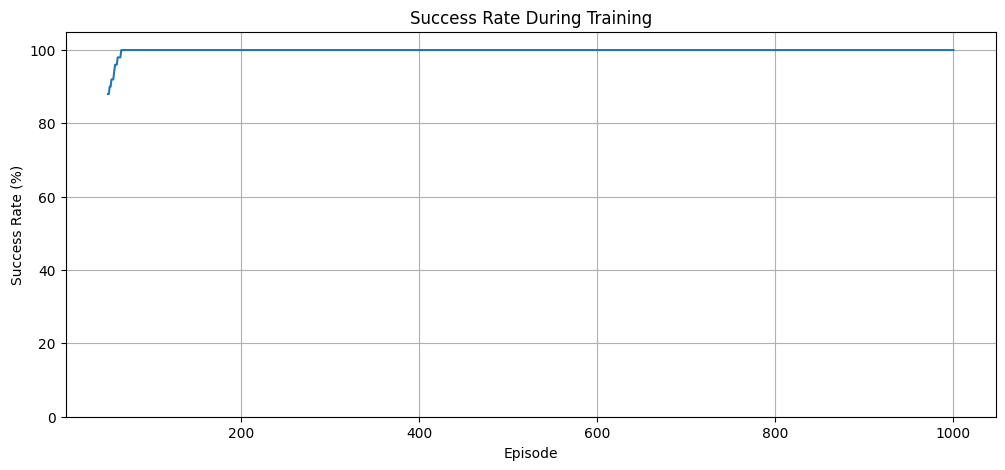

In [24]:
# Menghitung success rate menggunakan moving window
success_rate_moving = np.convolve(
    success_history,
    np.ones(WINDOW_SIZE) / WINDOW_SIZE,
    mode="valid"
) * 100

plt.figure(figsize=(12, 5))

plt.plot(
    range(WINDOW_SIZE, EPISODES + 1),
    success_rate_moving
)

plt.title("Success Rate During Training")
plt.xlabel("Episode")
plt.ylabel("Success Rate (%)")

plt.ylim(0, 105)
plt.grid(True)
plt.show()

## 6. Agent Evaluation

Setelah proses training selesai, agent dievaluasi untuk mengetahui kemampuan dalam mencapai Goal menggunakan strategi yang telah dipelajari.

Evaluasi dilakukan tanpa proses pembaruan Q-Table. Agent menggunakan greedy policy dengan epsilon sebesar 0 sehingga lebih mengutamakan tindakan dengan Q-Value tertinggi.

Pengujian dilakukan beberapa kali untuk mengukur success rate, average reward, dan average steps.

In [25]:
def run_evaluation_episode(q_table, max_steps=MAX_STEPS):
    """
    Menguji agent menggunakan greedy policy
    tanpa memperbarui Q-Table.
    """

    # Memulai dari posisi awal
    state = reset_environment()

    # Menyimpan jalur perjalanan agent
    path = [state]

    total_reward = 0
    done = False
    steps = 0

    for step_number in range(1, max_steps + 1):

        # Memilih action tanpa eksplorasi
        action = choose_action(
            state,
            q_table,
            epsilon=0
        )

        # Melakukan action pada environment
        next_state, reward, done = step(
            state,
            action
        )

        # Mengumpulkan reward
        total_reward += reward

        # Menyimpan posisi agent
        path.append(next_state)

        # Memperbarui state
        state = next_state

        steps = step_number

        # Berhenti jika Goal tercapai
        if done:
            break

    return {
        "success": done,
        "reward": total_reward,
        "steps": steps,
        "path": path
    }

In [26]:
# Jumlah episode evaluasi
EVAL_EPISODES = 100

# Mengatur random seed untuk evaluasi
random.seed(123)

# Menjalankan evaluasi
evaluation_results = []

for episode in range(EVAL_EPISODES):

    result = run_evaluation_episode(q_table)

    evaluation_results.append(result)


# Mengambil episode yang berhasil
successful_evaluations = [
    result
    for result in evaluation_results
    if result["success"]
]

# Menghitung success rate
evaluation_success_rate = (
    len(successful_evaluations) / EVAL_EPISODES
) * 100

# Menghitung rata-rata reward seluruh episode
evaluation_average_reward = np.mean([
    result["reward"]
    for result in evaluation_results
])

# Menghitung rata-rata langkah episode yang berhasil
if successful_evaluations:

    evaluation_average_steps = np.mean([
        result["steps"]
        for result in successful_evaluations
    ])

else:
    evaluation_average_steps = 0


# Menampilkan hasil
print("AGENT EVALUATION RESULTS")
print("=" * 35)

print("Total Evaluation Episodes:", EVAL_EPISODES)

print(
    "Successful Episodes:",
    len(successful_evaluations)
)

print(
    "Failed Episodes:",
    EVAL_EPISODES - len(successful_evaluations)
)

print(
    f"Success Rate: {evaluation_success_rate:.2f}%"
)

print(
    f"Average Reward: {evaluation_average_reward:.2f}"
)

print(
    f"Average Steps: {evaluation_average_steps:.2f}"
)

AGENT EVALUATION RESULTS
Total Evaluation Episodes: 100
Successful Episodes: 100
Failed Episodes: 0
Success Rate: 100.00%
Average Reward: 93.00
Average Steps: 8.00


BEST AGENT PATH
Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (3, 3), (3, 4), (4, 4)]
Total Steps: 8
Total Reward: 93


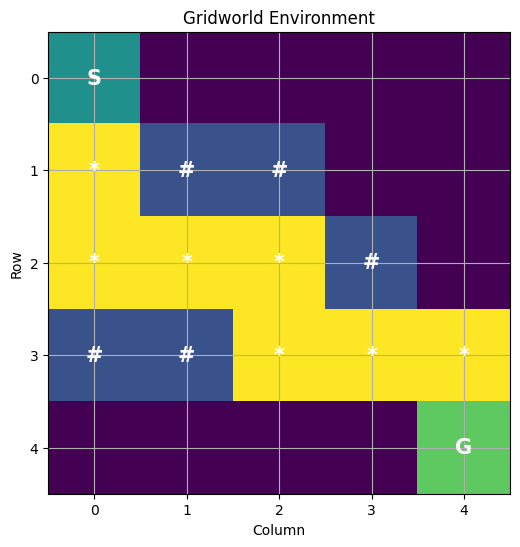

In [27]:
if successful_evaluations:

    # Memilih episode dengan jumlah langkah paling sedikit
    best_evaluation = min(
        successful_evaluations,
        key=lambda result: result["steps"]
    )

    best_path = best_evaluation["path"]

    print("BEST AGENT PATH")
    print("=" * 35)

    print("Path:", best_path)

    print("Total Steps:", best_evaluation["steps"])

    print("Total Reward:", best_evaluation["reward"])

    # Visualisasi jalur agent
    render_grid(path=best_path)

else:

    print("Agent belum berhasil menemukan Goal.")

### 6.1 Shortest Path Comparison Using BFS

Untuk mengetahui apakah jalur yang ditemukan agent sudah optimal, dilakukan perbandingan dengan jalur terpendek menggunakan Breadth-First Search (BFS).

BFS digunakan sebagai baseline untuk mencari jalur dengan jumlah langkah minimum dari Start menuju Goal tanpa melewati obstacle.

Hasil pencarian BFS kemudian dibandingkan dengan jalur yang ditemukan oleh agent Q-Learning.

In [28]:
from collections import deque


def find_shortest_path():

    # Menyimpan posisi dan jalur yang telah dilalui
    queue = deque([(START, [START])])

    # Menyimpan posisi yang sudah dikunjungi
    visited = {START}

    # Perubahan posisi berdasarkan action
    movements = {
        0: (-1, 0),  # Up
        1: (1, 0),   # Down
        2: (0, -1),  # Left
        3: (0, 1)    # Right
    }

    while queue:

        # Mengambil posisi dan jalur pertama
        current_position, path = queue.popleft()

        # Memeriksa apakah Goal sudah ditemukan
        if current_position == GOAL:
            return path

        row, col = current_position

        # Memeriksa seluruh kemungkinan pergerakan
        for action in ACTIONS:

            move_row, move_col = movements[action]

            new_position = (
                row + move_row,
                col + move_col
            )

            new_row, new_col = new_position

            # Memeriksa batas grid dan obstacle
            if (
                0 <= new_row < GRID_SIZE
                and 0 <= new_col < GRID_SIZE
                and new_position not in OBSTACLES
                and new_position not in visited
            ):

                visited.add(new_position)

                new_path = path + [new_position]

                queue.append(
                    (new_position, new_path)
                )

    return None

SHORTEST PATH USING BFS
Optimal Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4)]
Optimal Steps: 8


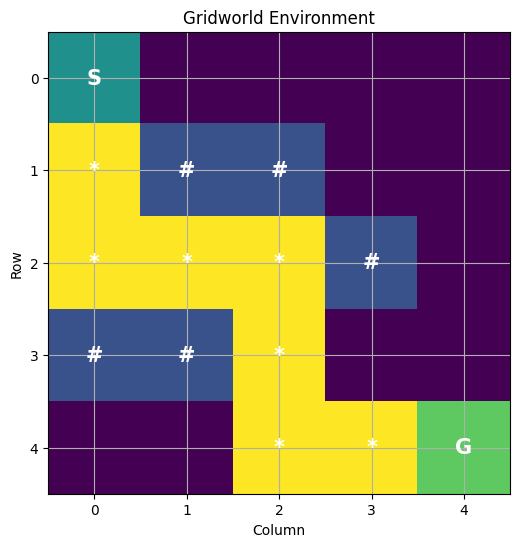

In [29]:
# Mencari jalur terpendek menggunakan BFS
optimal_path = find_shortest_path()

if optimal_path is not None:

    optimal_steps = len(optimal_path) - 1

    print("SHORTEST PATH USING BFS")
    print("=" * 35)

    print("Optimal Path:", optimal_path)

    print("Optimal Steps:", optimal_steps)

    # Visualisasi jalur terpendek
    render_grid(path=optimal_path)

else:

    print("Tidak ditemukan jalur menuju Goal.")

In [30]:
print("Q-LEARNING VS BFS COMPARISON")
print("=" * 40)

if successful_evaluations and optimal_path is not None:

    agent_steps = best_evaluation["steps"]

    print("Agent Steps:", agent_steps)
    print("Optimal Steps (BFS):", optimal_steps)

    difference = agent_steps - optimal_steps

    print("Step Difference:", difference)

    if difference == 0:

        print(
            "Result: Agent berhasil menemukan "
            "jalur dengan panjang optimal."
        )

    else:

        print(
            "Result: Agent berhasil mencapai Goal, "
            "tetapi jalurnya belum optimal."
        )

else:

    print(
        "Perbandingan belum dapat dilakukan "
        "karena agent belum berhasil mencapai Goal."
    )

Q-LEARNING VS BFS COMPARISON
Agent Steps: 8
Optimal Steps (BFS): 8
Step Difference: 0
Result: Agent berhasil menemukan jalur dengan panjang optimal.


### 6.2 Evaluation Analysis

Berdasarkan hasil evaluasi terhadap 100 episode, agent memperoleh success rate sebesar 100%. Seluruh episode berhasil mencapai Goal tanpa mengalami kegagalan.

Pengujian dilakukan menggunakan greedy policy dengan epsilon sebesar 0, sehingga agent memilih tindakan berdasarkan Q-Value yang telah dipelajari selama proses training. Selain itu, Q-Table tidak diperbarui selama evaluasi.

Dari hasil visualisasi, agent berhasil menemukan jalur dari Start menuju Goal dengan jumlah 8 langkah. Hasil tersebut dibandingkan dengan algoritma Breadth-First Search (BFS) yang juga menghasilkan jalur terpendek sebanyak 8 langkah.

Perbedaan jumlah langkah antara Q-Learning dan BFS adalah 0. Hal ini menunjukkan bahwa agent berhasil menemukan jalur optimal pada Gridworld Environment yang digunakan.

Agent memperoleh average reward sebesar 93 dan average steps sebesar 8. Nilai reward tersebut sesuai dengan reward system yang diterapkan, yaitu mendapatkan reward +100 ketika mencapai Goal dan penalty -1 untuk setiap pergerakan pada area normal sebelum mencapai Goal.

Secara keseluruhan, hasil evaluasi menunjukkan bahwa agent mampu memanfaatkan pengalaman selama training untuk menemukan jalur optimal secara konsisten pada environment yang sama.

## 7. Hyperparameter Experiments

Pada tahap ini dilakukan eksperimen untuk menganalisis pengaruh hyperparameter terhadap performa Q-Learning.

Eksperimen dilakukan dengan mengubah learning rate, epsilon decay, dan jumlah training episode.

Setiap konfigurasi diuji menggunakan tiga random seed yang berbeda. Hasil setiap konfigurasi kemudian dirata-ratakan untuk memperoleh gambaran performa yang lebih representatif.

Parameter yang tidak sedang diuji dipertahankan agar perbandingan dapat dilakukan secara lebih adil.

In [31]:
import pandas as pd

In [32]:
def train_q_learning(
    episodes,
    learning_rate,
    discount_factor,
    epsilon_start=1.0,
    epsilon_min=0.01,
    epsilon_decay=0.995,
    max_steps=100,
    seed=42
):
    """
    Melatih agent menggunakan Q-Learning
    dengan parameter yang dapat diubah.
    """

    # Mengatur random seed
    random.seed(seed)
    np.random.seed(seed)

    # Membuat Q-Table baru
    trained_q_table = np.zeros(
        (GRID_SIZE, GRID_SIZE, len(ACTIONS))
    )

    current_epsilon = epsilon_start

    # Menyimpan hasil training
    rewards = []
    steps_history = []
    successes = []
    epsilon_history = []

    # Proses training
    for episode in range(episodes):

        state = reset_environment()

        total_reward = 0
        done = False
        steps = 0

        for step_count in range(1, max_steps + 1):

            # Memilih action
            action = choose_action(
                state,
                trained_q_table,
                current_epsilon
            )

            # Berinteraksi dengan environment
            next_state, reward, done = step(
                state,
                action
            )

            # Memperbarui Q-Table
            update_q_table(
                q_table=trained_q_table,
                state=state,
                action=action,
                reward=reward,
                next_state=next_state,
                done=done,
                learning_rate=learning_rate,
                discount_factor=discount_factor
            )

            total_reward += reward
            state = next_state
            steps = step_count

            if done:
                break

        # Menyimpan hasil episode
        rewards.append(total_reward)
        steps_history.append(steps)
        successes.append(1 if done else 0)
        epsilon_history.append(current_epsilon)

        # Mengurangi epsilon
        current_epsilon = max(
            epsilon_min,
            current_epsilon * epsilon_decay
        )

    return {
        "q_table": trained_q_table,
        "rewards": rewards,
        "steps": steps_history,
        "successes": successes,
        "epsilon_history": epsilon_history,
        "final_epsilon": current_epsilon
    }

In [33]:
def evaluate_trained_agent(
    trained_q_table,
    eval_episodes=100,
    max_steps=100,
    seed=123
):
    """
    Mengevaluasi agent tanpa memperbarui Q-Table.
    """

    random.seed(seed)

    results = []

    for episode in range(eval_episodes):

        result = run_evaluation_episode(
            trained_q_table,
            max_steps=max_steps
        )

        results.append(result)

    # Mengambil episode yang berhasil
    successful_results = [
        result
        for result in results
        if result["success"]
    ]

    # Menghitung success rate
    success_rate = (
        len(successful_results) / eval_episodes
    ) * 100

    # Menghitung average reward
    average_reward = np.mean([
        result["reward"]
        for result in results
    ])

    # Menghitung average steps
    if successful_results:

        average_steps = np.mean([
            result["steps"]
            for result in successful_results
        ])

    else:
        average_steps = 0

    return {
        "success_rate": success_rate,
        "average_reward": average_reward,
        "average_steps": average_steps
    }

In [34]:
def run_configuration(
    episodes,
    learning_rate,
    discount_factor=0.95,
    epsilon_decay=0.995,
    seeds=(42, 43, 44)
):
    """
    Menjalankan satu konfigurasi eksperimen
    dengan tiga random seed.
    """

    run_results = []

    for seed in seeds:

        # Training agent
        training = train_q_learning(
            episodes=episodes,
            learning_rate=learning_rate,
            discount_factor=discount_factor,
            epsilon_decay=epsilon_decay,
            seed=seed
        )

        # Evaluasi agent
        evaluation = evaluate_trained_agent(
            trained_q_table=training["q_table"],
            eval_episodes=100,
            seed=seed + 1000
        )

        # Mengambil hasil 100 episode terakhir
        window = min(100, episodes)

        run_results.append({
            "training_reward": np.mean(
                training["rewards"][-window:]
            ),

            "training_success_rate": np.mean(
                training["successes"][-window:]
            ) * 100,

            "evaluation_success_rate": evaluation["success_rate"],

            "evaluation_average_reward": evaluation["average_reward"],

            "evaluation_average_steps": evaluation["average_steps"],

            "final_epsilon": training["final_epsilon"]
        })

    # Menghitung rata-rata dari tiga percobaan
    summary = {}

    for metric in run_results[0]:

        summary[metric] = np.mean([
            result[metric]
            for result in run_results
        ])

    return summary

### 7.1 Experiment A: Effect of Learning Rate

Eksperimen pertama dilakukan untuk mengetahui pengaruh learning rate terhadap kemampuan pembelajaran agent.

Learning rate yang digunakan adalah 0.01, 0.1, dan 0.5. Setiap konfigurasi dilatih selama 1.000 episode dengan parameter lainnya tetap.

Perbandingan dilakukan berdasarkan training reward, evaluation success rate, average reward, dan average steps.

In [35]:
learning_rates = [0.01, 0.1, 0.5]

alpha_results = []

for alpha in learning_rates:

    print(f"Running Learning Rate: {alpha}")

    result = run_configuration(
        episodes=1000,
        learning_rate=alpha,
        epsilon_decay=0.995
    )

    result["learning_rate"] = alpha

    alpha_results.append(result)


# Membuat tabel hasil
alpha_df = pd.DataFrame(alpha_results)

print("\nLEARNING RATE EXPERIMENT RESULTS")

display(
    alpha_df[
        [
            "learning_rate",
            "training_success_rate",
            "evaluation_success_rate",
            "evaluation_average_reward",
            "evaluation_average_steps"
        ]
    ].round(2)
)

Running Learning Rate: 0.01
Running Learning Rate: 0.1
Running Learning Rate: 0.5

LEARNING RATE EXPERIMENT RESULTS


,learning_rate,training_success_rate,evaluation_success_rate,evaluation_average_reward,evaluation_average_steps
0,0.01,100.0,100.0,93.0,8.0
1,0.10,100.0,100.0,93.0,8.0
2,0.50,100.0,100.0,93.0,8.0


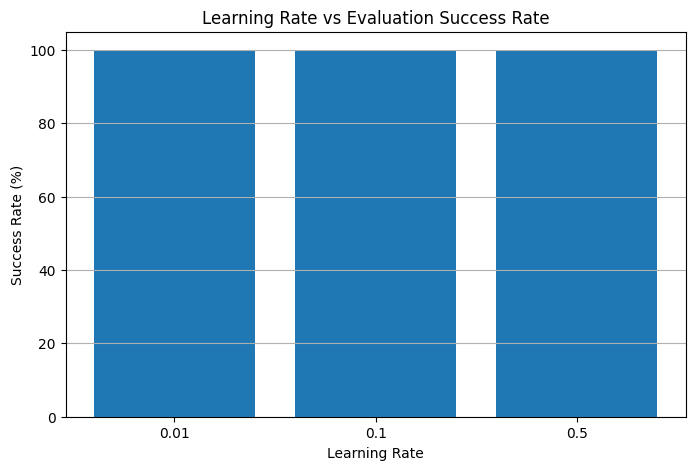

In [36]:
plt.figure(figsize=(8, 5))

plt.bar(
    alpha_df["learning_rate"].astype(str),
    alpha_df["evaluation_success_rate"]
)

plt.title("Learning Rate vs Evaluation Success Rate")
plt.xlabel("Learning Rate")
plt.ylabel("Success Rate (%)")

plt.ylim(0, 105)
plt.grid(axis="y")
plt.show()

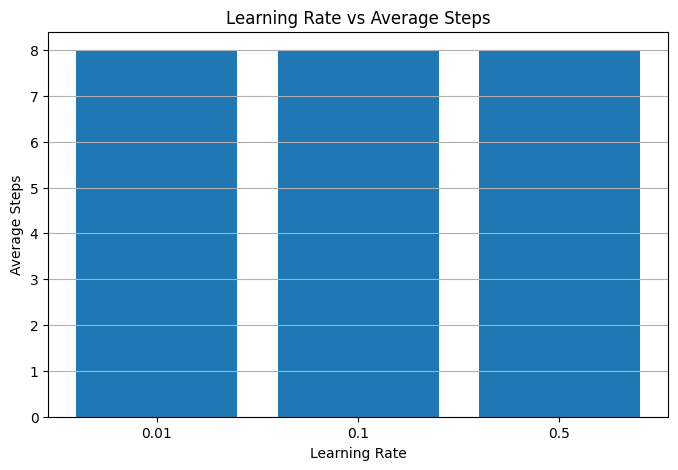

In [37]:
plt.figure(figsize=(8, 5))

plt.bar(
    alpha_df["learning_rate"].astype(str),
    alpha_df["evaluation_average_steps"]
)

plt.title("Learning Rate vs Average Steps")
plt.xlabel("Learning Rate")
plt.ylabel("Average Steps")

plt.grid(axis="y")
plt.show()

### 7.2 Experiment B: Effect of Epsilon Decay

Eksperimen kedua dilakukan untuk mengetahui pengaruh epsilon decay terhadap keseimbangan exploration dan exploitation.

Nilai epsilon decay yang dibandingkan adalah 0.99, 0.995, dan 0.999.

Nilai epsilon decay yang lebih kecil menyebabkan probabilitas eksplorasi berkurang lebih cepat. Sebaliknya, nilai yang lebih besar membuat agent mempertahankan eksplorasi lebih lama.

Performa setiap konfigurasi dievaluasi berdasarkan hasil training dan pengujian greedy policy.

In [38]:
epsilon_decays = [0.99, 0.995, 0.999]

epsilon_results = []

for decay in epsilon_decays:

    print(f"Running Epsilon Decay: {decay}")

    result = run_configuration(
        episodes=1000,
        learning_rate=0.1,
        epsilon_decay=decay
    )

    result["epsilon_decay"] = decay

    epsilon_results.append(result)


# Membuat tabel hasil
epsilon_df = pd.DataFrame(epsilon_results)

print("\nEPSILON DECAY EXPERIMENT RESULTS")

display(
    epsilon_df[
        [
            "epsilon_decay",
            "final_epsilon",
            "training_success_rate",
            "evaluation_success_rate",
            "evaluation_average_reward",
            "evaluation_average_steps"
        ]
    ].round(2)
)

Running Epsilon Decay: 0.99
Running Epsilon Decay: 0.995
Running Epsilon Decay: 0.999

EPSILON DECAY EXPERIMENT RESULTS


,epsilon_decay,final_epsilon,training_success_rate,evaluation_success_rate,evaluation_average_reward,evaluation_average_steps
0,0.99,0.01,100.0,100.0,93.0,8.0
1,1.00,0.01,100.0,100.0,93.0,8.0
2,1.00,0.37,100.0,100.0,93.0,8.0


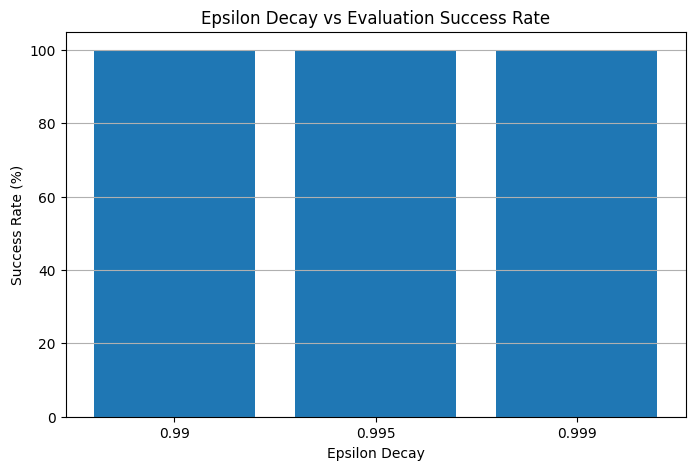

In [39]:
plt.figure(figsize=(8, 5))

plt.bar(
    epsilon_df["epsilon_decay"].astype(str),
    epsilon_df["evaluation_success_rate"]
)

plt.title("Epsilon Decay vs Evaluation Success Rate")
plt.xlabel("Epsilon Decay")
plt.ylabel("Success Rate (%)")

plt.ylim(0, 105)
plt.grid(axis="y")
plt.show()

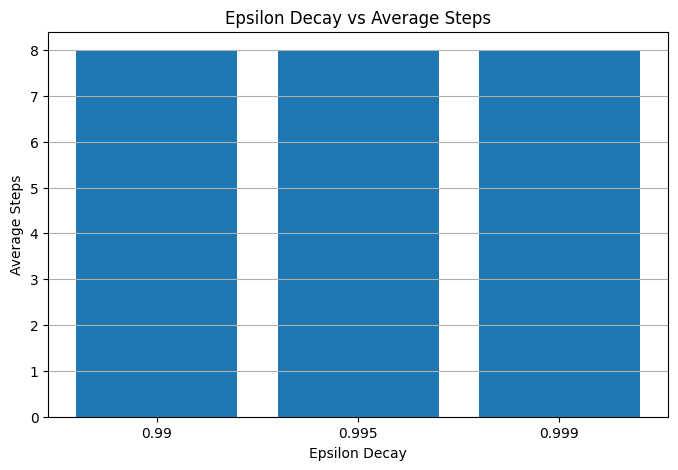

In [40]:
plt.figure(figsize=(8, 5))

plt.bar(
    epsilon_df["epsilon_decay"].astype(str),
    epsilon_df["evaluation_average_steps"]
)

plt.title("Epsilon Decay vs Average Steps")
plt.xlabel("Epsilon Decay")
plt.ylabel("Average Steps")

plt.grid(axis="y")
plt.show()

### 7.3 Experiment C: Effect of Training Episodes

Eksperimen ketiga dilakukan untuk menganalisis pengaruh jumlah episode terhadap performa agent.

Jumlah episode yang dibandingkan adalah 100, 500, 1.000, dan 2.000 episode.

Setiap konfigurasi menggunakan parameter Q-Learning yang sama, sedangkan jumlah interaksi agent dengan environment dibuat berbeda.

Hasil eksperimen digunakan untuk mengetahui bagaimana jumlah training episode memengaruhi kemampuan agent dalam mempelajari strategi navigasi.

In [41]:
episode_settings = [100, 500, 1000, 2000]

episode_results = []

for total_episodes in episode_settings:

    print(f"Running Episodes: {total_episodes}")

    result = run_configuration(
        episodes=total_episodes,
        learning_rate=0.1,
        epsilon_decay=0.995
    )

    result["episodes"] = total_episodes

    episode_results.append(result)


# Membuat tabel hasil
episode_df = pd.DataFrame(episode_results)

print("\nTRAINING EPISODES EXPERIMENT RESULTS")

display(
    episode_df[
        [
            "episodes",
            "training_reward",
            "training_success_rate",
            "evaluation_success_rate",
            "evaluation_average_reward",
            "evaluation_average_steps"
        ]
    ].round(2)
)

Running Episodes: 100
Running Episodes: 500
Running Episodes: 1000
Running Episodes: 2000

TRAINING EPISODES EXPERIMENT RESULTS


,episodes,training_reward,training_success_rate,evaluation_success_rate,evaluation_average_reward,evaluation_average_steps
0,100,-31.62,93.33,100.0,93.0,8.0
1,500,89.10,100.00,100.0,93.0,8.0
2,1000,92.74,100.00,100.0,93.0,8.0
3,2000,92.72,100.00,100.0,93.0,8.0


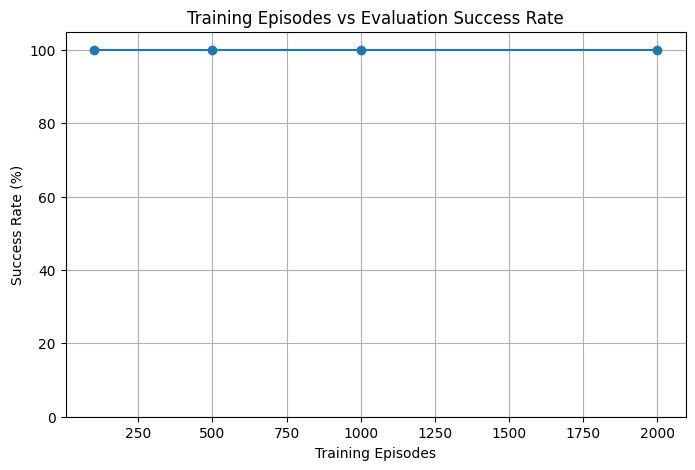

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    episode_df["episodes"],
    episode_df["evaluation_success_rate"],
    marker="o"
)

plt.title("Training Episodes vs Evaluation Success Rate")
plt.xlabel("Training Episodes")
plt.ylabel("Success Rate (%)")

plt.ylim(0, 105)
plt.grid(True)
plt.show()

In [43]:
# Membuat tabel ringkasan seluruh eksperimen

all_experiments = []

# Learning Rate
for _, row in alpha_df.iterrows():

    all_experiments.append({
        "Experiment": "Learning Rate",
        "Configuration": row["learning_rate"],
        "Success Rate": row["evaluation_success_rate"],
        "Average Reward": row["evaluation_average_reward"],
        "Average Steps": row["evaluation_average_steps"]
    })


# Epsilon Decay
for _, row in epsilon_df.iterrows():

    all_experiments.append({
        "Experiment": "Epsilon Decay",
        "Configuration": row["epsilon_decay"],
        "Success Rate": row["evaluation_success_rate"],
        "Average Reward": row["evaluation_average_reward"],
        "Average Steps": row["evaluation_average_steps"]
    })


# Training Episodes
for _, row in episode_df.iterrows():

    all_experiments.append({
        "Experiment": "Training Episodes",
        "Configuration": row["episodes"],
        "Success Rate": row["evaluation_success_rate"],
        "Average Reward": row["evaluation_average_reward"],
        "Average Steps": row["evaluation_average_steps"]
    })


# Membuat DataFrame
comparison_df = pd.DataFrame(all_experiments)

print("OVERALL EXPERIMENT COMPARISON")

display(
    comparison_df.style.format({
        "Configuration": "{:.3f}",
        "Success Rate": "{:.2f}",
        "Average Reward": "{:.2f}",
        "Average Steps": "{:.2f}"
    })
)

OVERALL EXPERIMENT COMPARISON


,Experiment,Configuration,Success Rate,Average Reward,Average Steps
0,Learning Rate,0.010,100.00,93.00,8.00
1,Learning Rate,0.100,100.00,93.00,8.00
2,Learning Rate,0.500,100.00,93.00,8.00
3,Epsilon Decay,0.990,100.00,93.00,8.00
4,Epsilon Decay,0.995,100.00,93.00,8.00
5,Epsilon Decay,0.999,100.00,93.00,8.00
6,Training Episodes,100.000,100.00,93.00,8.00
7,Training Episodes,500.000,100.00,93.00,8.00
8,Training Episodes,1000.000,100.00,93.00,8.00
9,Training Episodes,2000.000,100.00,93.00,8.00


## 8. Experiment Analysis

### 8.1 Pengaruh Learning Rate

Berdasarkan hasil eksperimen, perubahan learning rate memberikan pengaruh terhadap performa agent.

Konfigurasi learning rate yang menghasilkan performa terbaik adalah [hasil eksperimen].

Hal tersebut ditunjukkan oleh evaluation success rate sebesar [nilai aktual] dan average steps sebesar [nilai aktual].

### 8.2 Pengaruh Epsilon Decay

Berdasarkan eksperimen epsilon decay, konfigurasi yang memberikan hasil terbaik adalah [hasil eksperimen].

Perbedaan nilai epsilon decay memengaruhi durasi eksplorasi agent selama training.

Hasil tersebut menunjukkan bahwa [analisis berdasarkan hasil aktual].

### 8.3 Pengaruh Jumlah Training Episodes

Berdasarkan eksperimen jumlah episode, konfigurasi [hasil eksperimen] menghasilkan performa terbaik.

Hasil menunjukkan bahwa peningkatan jumlah episode [analisis berdasarkan hasil aktual].

### 8.4 Overall Experiment Findings

Berdasarkan seluruh eksperimen, dapat diketahui bahwa performa Q-Learning dipengaruhi oleh pemilihan hyperparameter.

Konfigurasi yang paling sesuai untuk Gridworld Environment ini adalah [hasil eksperimen], dengan mempertimbangkan success rate, average reward, average steps, dan efisiensi training.

## 9. Overall Results and Discussion

### 9.1 Training Performance Analysis

Berdasarkan proses training selama 1.000 episode, agent berhasil mencapai Goal pada 994 episode, dengan overall success rate sebesar 99.40%.

Sementara itu, success rate pada 100 episode terakhir mencapai 100%. Hal ini menunjukkan bahwa agent mengalami peningkatan kemampuan selama proses pembelajaran.

Rata-rata reward selama training sebesar 74.58, sedangkan rata-rata jumlah langkah pada episode yang berhasil adalah 12.08.

Grafik reward menunjukkan bahwa pada awal training agent masih sering memperoleh reward negatif. Seiring bertambahnya episode, moving average reward meningkat dan cenderung stabil.

Penurunan epsilon dari 1.0 menuju 0.01 juga menunjukkan bahwa agent secara bertahap mengurangi eksplorasi dan lebih banyak memanfaatkan pengetahuan yang diperoleh selama training.

### 9.2 Evaluation Performance Analysis

Evaluasi dilakukan menggunakan greedy policy terhadap 100 episode pengujian tanpa memperbarui Q-Table.

Hasil evaluasi menunjukkan bahwa seluruh 100 episode berhasil mencapai Goal, dengan success rate sebesar 100%.

Agent memperoleh average reward sebesar 93 dan membutuhkan rata-rata 8 langkah untuk mencapai Goal.

Hasil ini menunjukkan bahwa agent mampu memanfaatkan Q-Value yang telah dipelajari selama training untuk menghasilkan strategi navigasi yang efektif.

### 9.3 Optimal Path Analysis

Untuk mengetahui apakah strategi agent sudah optimal, jalur yang ditemukan Q-Learning dibandingkan dengan jalur terpendek menggunakan Breadth-First Search (BFS).

Hasil perbandingan menunjukkan bahwa kedua metode menghasilkan panjang jalur sebanyak 8 langkah.

Dengan demikian, Q-Learning berhasil menemukan jalur dengan jumlah langkah minimum pada Gridworld Environment yang digunakan.

### 9.4 Hyperparameter Experiment Analysis

Eksperimen learning rate menunjukkan bahwa nilai 0.01, 0.1, dan 0.5 menghasilkan performa evaluasi yang sama, yaitu success rate 100%, average reward 93, dan average steps 8.

Eksperimen epsilon decay juga menunjukkan hasil evaluasi yang sama untuk konfigurasi 0.99, 0.995, dan 0.999. Meskipun memiliki kecepatan penurunan eksplorasi yang berbeda, seluruh konfigurasi berhasil menghasilkan strategi navigasi optimal.

Pada eksperimen jumlah episode, training selama 100 episode menghasilkan training success rate sebesar 93.33%. Sementara itu, konfigurasi 500, 1.000, dan 2.000 episode menghasilkan training success rate sebesar 100% pada periode pengamatan terakhir.

Training reward meningkat dari -31.62 pada 100 episode menjadi 89.10 pada 500 episode dan 92.74 pada 1.000 episode. Pada 2.000 episode, training reward sebesar 92.72, sehingga tidak terdapat peningkatan berarti dibandingkan 1.000 episode.

Hasil tersebut menunjukkan bahwa penambahan jumlah episode membantu proses pembelajaran hingga mencapai kondisi yang stabil. Namun, peningkatan jumlah episode secara berlebihan tidak selalu memberikan peningkatan performa yang berarti.

### 9.5 Project Limitations

Meskipun agent berhasil menemukan jalur optimal, project ini memiliki beberapa keterbatasan:

1. Environment yang digunakan hanya memiliki ukuran 5 × 5 sehingga kompleksitas navigasinya relatif rendah.
2. Posisi Start, Goal, dan obstacle bersifat tetap sehingga agent hanya diuji pada satu konfigurasi environment.
3. Q-Learning menggunakan Q-Table sehingga pendekatan ini kurang sesuai untuk environment dengan jumlah state yang sangat besar.
4. Hasil eksperimen hyperparameter menunjukkan performa yang sama pada seluruh konfigurasi tertentu. Hal ini membatasi kemampuan untuk membedakan pengaruh parameter terhadap performa akhir pada environment yang digunakan.
5. Pengujian belum mencakup kemampuan agent dalam menghadapi perubahan posisi obstacle atau environment yang berbeda.

Pengembangan selanjutnya dapat dilakukan dengan menggunakan grid yang lebih besar, variasi obstacle, atau environment yang berbeda untuk menguji kemampuan generalisasi agent.

## 10. Conclusion

Berdasarkan implementasi dan hasil eksperimen, algoritma Q-Learning berhasil diterapkan pada Gridworld Environment untuk menyelesaikan permasalahan navigasi agent dari titik Start menuju Goal dengan menghindari obstacle.

Agent mempelajari strategi navigasi melalui interaksi dengan environment menggunakan mekanisme state, action, reward, policy, dan value. Proses pembelajaran dilakukan menggunakan Q-Table dan epsilon-greedy policy, sehingga agent dapat melakukan eksplorasi dan memanfaatkan pengalaman yang telah diperoleh.

Setelah training selama 1.000 episode, agent memperoleh overall success rate sebesar 99.40%, dengan success rate sebesar 100% pada 100 episode terakhir.

Hasil evaluasi menunjukkan bahwa agent berhasil mencapai Goal pada seluruh 100 episode pengujian. Agent membutuhkan rata-rata 8 langkah dan memperoleh average reward sebesar 93.

Perbandingan dengan Breadth-First Search menunjukkan bahwa agent berhasil menemukan jalur dengan panjang yang sama dengan jalur terpendek, yaitu 8 langkah. Hal ini menunjukkan bahwa Q-Learning mampu mempelajari strategi navigasi optimal pada environment yang digunakan.

Eksperimen hyperparameter menunjukkan bahwa learning rate dan epsilon decay yang diuji menghasilkan performa evaluasi yang sama. Sementara itu, peningkatan jumlah episode membantu agent mencapai proses pembelajaran yang lebih stabil, meskipun penambahan episode dari 1.000 menjadi 2.000 tidak memberikan peningkatan performa yang berarti.

Secara keseluruhan, project ini berhasil mendemonstrasikan bagaimana Reinforcement Learning memungkinkan agent mempelajari strategi melalui proses interaksi dan feedback dari environment tanpa memerlukan data berlabel secara langsung.

## 11. References

1. Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press.
   http://incompleteideas.net/book/the-book-2nd.html

2. NumPy Developers. NumPy Documentation.
   https://numpy.org/doc/

3. Matplotlib Developers. Matplotlib Documentation.
   https://matplotlib.org/stable/

4. Pandas Development Team. pandas Documentation.
   https://pandas.pydata.org/docs/